# Amelia Polak 23362995, Mateusz Przywozny 23365021, Jakub Bolka 23378247
# Execution status: # Execution status: the notebook ran from a fresh kernel to completion without errors.
# Sources: https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html ; https://debuggercafe.com/implementing-vgg11-from-scratch-using-pytorch/ ; full references and AI-use log are in the accompanying report.

STEP 1: LOAD AND PREPARE THE DATA (Mateusz):

Wrote code to download the dataset and split it into training, validation and test data.
The dataset is built into the torchvision framework.

Does the code run/work: YES

Sources (tutorials used for code): 
https://www.digitalocean.com/community/tutorials/vgg-from-scratch-pytorch
https://www.youtube.com/watch?v=ovZ_54IUSU4
https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html

In [1]:
#import necessary libraries
import numpy as np #to work with arrays
import torch #deep learning framework
import torchvision.datasets as datasets #access to built in datasets, cifar10 is one of them
import torchvision.transforms as transform #to transform images
from torch.utils.data import Subset, DataLoader #to split data and load it later on

mean=[0.49139968, 0.48215827 ,0.44653124] #mean values for red,green and blue in cifar10
std=[0.24703233, 0.24348505, 0.26158768] #standard deviations for each colour
#values in range 0.0-1.0 (tensors)

#Transform image : VGG takes 32x32 images (dataset consists of 32x32 images),normalise for accuracy
#Split into two transforms(one for training data, other for the rest)
training_transform = transform.Compose([
    #transform.Resize((224,224)), #resize the image to 224x224

    transform.RandomHorizontalFlip(), #train on a flipped image
    transform.RandomRotation(20), #image may be slightly rotated
    transform.ToTensor(), #take image colours (0-255) and shrink the range to (0.0-1.0)-easier to read
    transform.Normalize(torch.Tensor(mean), torch.tensor(std)) #normalise to prevent the model from getting confused, eg when part of the image is super bright
])

#for validation and test data dont flip or rotate the images
test_transform = transform.Compose([
    #transform.Resize((224,224)),
    transform.ToTensor(),
    transform.Normalize(torch.Tensor(mean), torch.tensor(std))
])

#get data from the dataset (its split into training and test by default)
#root - name of the folder data are/will be in
#train-is data trained
#download = True ->download into the folder directly
training_full=datasets.CIFAR10(root = './dataset', train=True, download=True, transform=training_transform)
validation_full = datasets.CIFAR10(root = './dataset', train=True, download=True, transform=test_transform) #get the whole training data but dont modify as much as training data
test_set=datasets.CIFAR10(root = './dataset', train=False, download=True, transform=test_transform)

#create a list using permutations to select images at random, use random number for seed so it stays consistent
#indices =torch.randperm(50000,generator=torch.Generator().manual_seed(10))

#split into training and validation, indices access the same images
#training_set= Subset(training_full, indices[:45000])
#validation_set = Subset(validation_full, indices[45000:])


#Load all 3 sets
#use batch size 32 as default
#training_load = DataLoader(training_set, batch_size=32,shuffle=True) #shuffle training data for different order each epoch
#validation_load = DataLoader(validation_set, batch_size=32)
#test_load = DataLoader(test_set, batch_size=32)

STEP 2:Build the CNN Layers(Amelia)

For this part I created a  VGG-11 Cnn using Pytorch.We chose VGG-11 instead of  using the full VGG-16 model as it has fewer convolutional layers.I added the convolutional layers ,ReLu activation functions ,max pooling and fully connected layers.

VGG-11 has:
* 8 convolutional layers -->learn features from images
* 3 fully connected layers -->used for classification
* 4096 neurons --> in first two fully connected layers 
* 5 max pooling layers --> reducing  the img size while keeping important features
* ReLU(activation function) -->helps the nn learn more complex patterns
* Dropout(0.5) --> helps reduce overfitting durng training
* Final layer has 10 outputs --> one for each CIFAR-10 class
* Images retain their original 32 × 32 resolution

Resources:
Reused code  + understanding the  VGG11 architecture :
* https://debuggercafe.com/implementing-vgg11-from-scratch-using-pytorch/
* https://www.kaggle.com/code/rightway11/vgg11tutorial

Understanding the VGG11 architecture:
* https://medium.com/@kfallon2010/ml-w-mnist-part-4-13c3e5d15c9f
* https://viso.ai/deep-learning/vgg-very-deep-convolutional-networks
* ChatGPT



Does the code work: Yes , I tested  the model using  random rgb image with size 32x32 .
* Input shape: (1,3,32,32)
* Output shape: (1,10)
* Parameters: 28,144,010


In [2]:
import torch.nn as nn #library for creating a nn layers 

class VGG11(nn.Module):
    
    def __init__(self,in_channels=3, num_classes=10):#3rgb and 10 cifar10 classes
        super().__init__()#initalization of parent class
        self.in_channels = in_channels # storing the  number of input channels 
        self.num_classes = num_classes #storing the number of classes 
        
        self.conv_layers = nn.Sequential(
            nn.Conv2d(self.in_channels,64,kernel_size=3,padding=1),#input channels to 64 output channels
            nn.ReLU(),#activation function
            nn.MaxPool2d(kernel_size=2,stride=2),#reducing img size by half
            
            nn.Conv2d(64,128,kernel_size=3,padding=1),#64 channels in , 128 out
            nn.ReLU(),#activation fucntion
            nn.MaxPool2d(kernel_size=2,stride=2),#reduce img size 
            
            nn.Conv2d(128,256,kernel_size=3,padding=1),#increasing channels to 256
            nn.ReLU(),#activation functino
            nn.Conv2d(256,256,kernel_size=3,padding=1),#keep 256 channels
            nn.ReLU(),#activation function
            nn.MaxPool2d(kernel_size=2,stride=2),#reduce img size 
            
            nn.Conv2d(256,512,kernel_size=3,padding=1),#increasing channels to 512
            nn.ReLU(),#activation functino
            nn.Conv2d(512,512,kernel_size=3,padding=1),#keep 512 channels
            nn.ReLU(),#activation function
            nn.MaxPool2d(kernel_size=2,stride=2),#reduce img size 
            
            nn.Conv2d(512,512,kernel_size=3,padding=1),#7th convolution layer
            nn.ReLU(),#activation function
            nn.Conv2d(512,512,kernel_size=3,padding=1),#last convolution - 8th
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)# 5th final max pooling
            )    
        self.avgpool = nn.AdaptiveAvgPool2d((1,1))#make the feature map 1x1 before classification
        
        #fully connected layers for classification
        self.linear_layers = nn.Sequential( 
            nn.Flatten(),#turns the feature maps into one vector
            nn.Linear(512,4096),#takes 512 features and produces 4096 outputs
            nn.ReLU(),#activation function
            nn.Dropout(0.5),#ignoring the 50% of neurons during training in order to reduce the overfitting
            nn.Linear(4096,4096),#taking 4096 values and producing 4096 values
            nn.ReLU(),#activation fucntion
            nn.Dropout(0.5),#ignoring the 50% of neurons during training in order to reduce the overfitting
            nn.Linear(4096,self.num_classes)#produce 10 scores becasue CIRFAR10 has 10 classes 
                
        )
    #how img moves through the network
    def forward(self,x):#x is the input img
        x = self.conv_layers(x)#passing the img throught the convolution layers 
        x = self.avgpool(x)#making feature map 1 x 1
        x = self.linear_layers(x)#passing the img through connected layers 
        return x #return the 10 class scores
                
model = VGG11() #creating our VGG11 model
print("Model created successfully")#confirmation
        

Model created successfully


In [3]:
#Checking if our model works 

import torch #library for working with tensors 
#count the total parameters in our model
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

#creating one random RGB image with size 32x32
image_tensor = torch.randn(1, 3, 32, 32)

#testing model without training
model.eval()
with torch.no_grad():
    outputs = model(image_tensor)

#print the input and output shapes
print("Input shape:", image_tensor.shape)
print("Output shape:", outputs.shape)

Total parameters: 28,144,010
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])


STEP 3: Training the CNN (Jakub)

For my part I added the training and validation code for our VGG-11 CNN using PyTorch. This uses the data loaders prepared by Mateusz and the network created by Amelia.

 During training, the model predicts the classes of the images, calculates its error and updates its weights to improve its predictions.
 

My training section includes:

- CrossEntropyLoss --> measures the error between the model's class scores and the correct labels

- Adam optimiser --> updates the model's weights using the calculated gradients

- Learning rate of 0.0001 --> controls the size of the weight updates

- 10 epochs --> the model passes through the training dataset 10 times

- Batch size of 32 --> uses the batches provided by Mateusz's data loader

- Backpropagation --> calculates how each weight contributes to the error

- Validation after each epoch --> checks performance on images that are not used to update the weights

- Saving the best model --> saves the weights with the lowest validation loss

- Loss and accuracy plots --> show how training and validation performance change over the epochs


I also added a final evaluation section to calculate test accuracy, precision, recall, F1 scores and a confusion matrix. This will be run after selecting the final model using the validation results.

Completed experiment:

- Compared learning rates of 0.0001 and 0.001 while keeping the other settings fixed
- Compared the validation results and learning curves to investigate how learning rate affects training

Resources:

- PyTorch Training a Classifier tutorial:
  https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html

- PyTorch CrossEntropyLoss documentation:
  https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html

- PyTorch Saving and Loading Models tutorial:
  https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html

- ChatGpt Prompts Included in Document


Does the code work:
The initial quick check completed successfully, followed by the full experiments and final evaluation.

In [4]:
# Standard Python libraries
import copy  # Make independent dataset views with different transforms.
import csv  # Write tables of measured results.
import json  # Save settings and epoch histories.
import random  # Control Python randomness.
import time  # Measure epoch durations.
from datetime import datetime  # Give each execution a separate results folder.
from pathlib import Path  # Build portable file paths.

# Numerical calculations and plotting
import numpy as np  # Calculate preprocessing statistics and evaluation metrics.
import matplotlib.pyplot as plt  # Draw curves and the confusion matrix.

# PyTorch and image preprocessing
import torch  # Run tensor operations and automatic differentiation.
import torch.nn as nn  # Define layers and classification loss.
from torch.utils.data import DataLoader, Subset  # Load batches from selected dataset indices.
import torchvision.datasets as datasets  # Download and read CIFAR-10.
import torchvision.transforms as transform  # Convert, augment and normalise images.

# Cross-validation splitting
from sklearn.model_selection import StratifiedKFold  # Preserve class proportions in rotating validation folds.

Experiment Settings

For this experiment I compare two learning rates to investigate how they affect training and validation performance.

The settings are:
- Optimiser --> Adam
- Learning rates --> 0.0001 and 0.001
- Cross-validation --> three stratified folds
- Training duration --> ten epochs per fold
- Batch size --> 32 images

To make the comparison fair, I keep the architecture, fold membership, batch size, augmentation and epoch budget the same for both learning rates. Corresponding folds also use matching starting seeds. Each fold starts with fresh model weights and a new optimiser.

Before the full experiment, I run a quick check using one epoch and only two batches per training and validation pass. This checks that the code executes successfully; its scores are not used to compare model performance.

The full experiment processes every training and validation batch for all ten epochs.

In [5]:
# Choose the short check or the full experiment
QUICK_CHECK = False  # Set False after the short execution check succeeds.
FULL_EPOCHS = 10  # Agreed full-run budget for both learning rates and the final model.
FOLDS = 3  # Train on about 33,333 development images and validate on about 16,667 per fold.

# Settings shared by all independent training runs
LEARNING_RATES = [0.0001, 0.001]  # Vary only this setting in the first controlled comparison.
BATCH_SIZE = 32  # Retain Mateusz's batch size.
SEED = 10  # Keep fold membership and corresponding run seeds repeatable.

# Keep final training and testing separate from experimentation
RUN_FINAL_EVALUATION = False  # Enable only after reviewing the completed full comparison.

# Apply the quick-check limits only when requested
EPOCHS = 1 if QUICK_CHECK else FULL_EPOCHS  # Use a short check or the chosen full budget.
MAX_BATCHES = 2 if QUICK_CHECK else None  # Limit only the quick check; full runs use all images.

# Select the device and label this execution
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Use CUDA when available.
mode_name = "quick_check" if QUICK_CHECK else "full_experiment"  # Keep check results visibly separate.

# Create a separate folder for this execution
run_dir = Path("cnn_results") / f"{mode_name}_{datetime.now():%Y%m%d_%H%M%S_%f}"  # Avoid overwriting earlier runs.
run_dir.mkdir(parents=True, exist_ok=False)  # Create a new results directory.

# Save the settings alongside the results
settings = dict(quick_check=QUICK_CHECK, folds=FOLDS, epochs=EPOCHS,  # Record whether this is a short check, together with fold and epoch settings.
                learning_rates=LEARNING_RATES, batch_size=BATCH_SIZE, seed=SEED,  # Record both compared learning rates, the batch size and the random seed.
                max_batches=MAX_BATCHES, optimizer="Adam", weight_decay=0,  # Record the short-check limit, Adam choice and absence of weight decay.
                device=str(device), torch_version=str(torch.__version__))  # Record the actual experimental setup.
(run_dir / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")  # Persist settings before training.
print(f"Mode: {mode_name}; device: {device}; epochs per fold: {EPOCHS}; output: {run_dir.resolve()}")  # Confirm the setup.

Mode: full_experiment; device: cuda; epochs per fold: 10; output: C:\Users\bolka\CS4287-Assignment01\cnn_results\full_experiment_20261028_210520_455468


Prepare the Rotating Folds

For this part I replace the original fixed training and validation split with three-fold stratified cross-validation. Stratification keeps the proportion of images from each class similar across the folds.

Each run uses:
- Approximately 33,333 images for training
- Approximately 16,667 images for validation

The sizes vary slightly because 50,000 cannot be divided equally into three groups. The validation group changes between runs, so every development image is used for validation once per learning-rate setting.

For each fold, I calculate the RGB mean and standard deviation using only its training images. These values normalise both the training and validation images and are reused for both learning rates.

Random flips and rotations are applied only to training images in the augmented experiment. Validation images are not augmented.

Resources: Creating stratified folds
- Scikit-learn — StratifiedKFold:
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
  

In [6]:
# Use the existing dataset objects created by Mateusz; do not download or recreate them here.
assert len(training_full) == 50000 and len(validation_full) == 50000  # Require the full development dataset, not old 45,000/5,000 subsets.
assert training_full.targets == validation_full.targets  # Require identical sample ordering in both transform views.
assert len(test_set) == 10000  # Keep the official CIFAR-10 test partition separate.

# Read the class names and labels
classes = training_full.classes  # Preserve the original ten-class order.
targets = np.asarray(training_full.targets)  # Read labels for stratified splitting.


# Function: channel_statistics
# Calculate the RGB mean and standard deviation for a training subset.
# Only the supplied training indices contribute; held-out images are excluded.
# Small chunks keep the temporary memory use manageable.
# Returns two lists: the three channel means and three standard deviations.
def channel_statistics(raw_images, indices, chunk_size=500):  # Fit normalisation using only the requested training images.
    channel_sum = np.zeros(3, dtype=np.float64)  # Accumulate RGB pixel values.
    channel_square_sum = np.zeros(3, dtype=np.float64)  # Accumulate squared values for the variance.
    pixel_count = 0  # Count pixels per channel.

    # Accumulate pixel statistics in manageable chunks
    for start in range(0, len(indices), chunk_size):  # Avoid converting the whole dataset to floating point at once.
        images = raw_images[indices[start:start + chunk_size]].astype(np.float64) / 255.0  # Match ToTensor's pixel scale.
        channel_sum += images.sum(axis=(0, 1, 2))  # Sum all pixels separately for each colour.
        channel_square_sum += np.square(images).sum(axis=(0, 1, 2))  # Sum squared pixels per colour.
        pixel_count += images.shape[0] * images.shape[1] * images.shape[2]  # Count pixels contributing to each channel.

    # Convert the accumulated totals into normalisation statistics
    mean = channel_sum / pixel_count  # Calculate the channel means.
    variance = channel_square_sum / pixel_count - np.square(mean)  # Calculate population variances.
    std = np.sqrt(np.maximum(variance, 1e-12))  # Protect against tiny floating-point variance errors.

    return mean.tolist(), std.tolist()  # Return values accepted by torchvision normalisation.


# Function: make_transforms
# Build separate preprocessing pipelines for training and evaluation.
# Training includes random flips and rotations; evaluation does not.
# Both pipelines use the means and standard deviations fitted to training data.
# Returns the training transform and the evaluation transform.
def make_transforms(mean, std):  # Use the same normalisation for matching training and evaluation views.

    # Training preprocessing includes augmentation
    training_transform = transform.Compose([  # Build the ordered augmentation and preprocessing operations for training.
        transform.RandomHorizontalFlip(),  # Flip training images randomly for augmentation.
        transform.RandomRotation(20),  # Rotate only training images by up to 20 degrees.
        transform.ToTensor(),  # Convert uint8 RGB images to channel-first floats in [0, 1].
        transform.Normalize(mean, std),  # Centre and scale channels using training-only statistics.
    ])  # Compose the training preprocessing operations.

    # Evaluation preprocessing is deterministic
    evaluation_transform = transform.Compose([  # Build deterministic validation and test preprocessing without augmentation.
        transform.ToTensor(),  # Convert validation or test images without random augmentation.
        transform.Normalize(mean, std),  # Use the corresponding training statistics.
    ])  # Compose deterministic evaluation preprocessing.

    return training_transform, evaluation_transform  # Return both dataset views' transformations.

# Prepare the same rotating splits for both learning rates


splitter = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)  # Create repeatable class-balanced splits.
fold_splits = list(splitter.split(np.zeros(len(targets)), targets))  # Reuse identical splits for both learning rates.
fold_statistics = []  # Cache preprocessing statistics so both settings use the same values.

# Process each development-data split independently
for fold, (train_indices, val_indices) in enumerate(fold_splits, start=1):  # Prepare every fold before training.
    assert not np.intersect1d(train_indices, val_indices).size  # Ensure no image appears on both sides of this fold.
    mean, std = channel_statistics(training_full.data, train_indices)  # Fit RGB statistics to the training portion only.
    fold_statistics.append(dict(mean=mean, std=std))  # Retain the fold-specific fitted preprocessing.
    print(f"Fold {fold}: training={len(train_indices)}, validation={len(val_indices)}")  # Confirm the rotating split sizes.
(run_dir / "fold_preprocessing.json").write_text(json.dumps(fold_statistics, indent=2), encoding="utf-8")  # Save fitted statistics.


Fold 1: training=33333, validation=16667
Fold 2: training=33333, validation=16667
Fold 3: training=33334, validation=16666


622

In [7]:
# Reset the random-number generators before training a fresh model.
# Matching seeds help compare learning rates from matching initial weights.
# Also configure cuDNN to improve repeatability when using a CUDA GPU.
def seed_everything(seed):  # Reset randomness before each independent model run.

    # Reset Python, NumPy and PyTorch randomness
    random.seed(seed)  # Seed Python's random-number generator.
    np.random.seed(seed)  # Seed NumPy's random-number generator.
    torch.manual_seed(seed)  # Seed PyTorch model initialisation, augmentation and loader operations.

    # Configure or release GPU resources when CUDA is available
    if torch.cuda.is_available():  # Apply CUDA settings when a GPU exists.
        torch.cuda.manual_seed_all(seed)  # Seed every CUDA device.

    # Prefer repeatable convolution behaviour
    torch.backends.cudnn.benchmark = False  # Avoid timing-based selection of convolution algorithms.
    torch.backends.cudnn.deterministic = True  # Request deterministic cuDNN algorithms where available.
    # Exact reproducibility across different devices and library versions is not guaranteed.

# Run one training or evaluation pass over a data loader.
# With an optimiser: enable dropout, calculate gradients and update weights.
# Without an optimiser: disable dropout and calculate metrics without learning.
# The optional batch limit is used only for the initial quick check.
# Returns the mean per-image loss and accuracy as a fraction from zero to one.
def run_epoch(model, loader, criterion, optimizer=None, max_batches=None):  # Train or evaluate one pass with image-weighted metrics.

    # Choose training or evaluation behaviour
    training = optimizer is not None  # Supplying an optimiser selects training mode.
    model.train(training)  # Enable dropout for training and disable it for evaluation.
    total_loss, total_correct, total_images = 0.0, 0, 0  # Initialise epoch totals.

    # Process the images, tracking gradients only for training
    with torch.set_grad_enabled(training):  # Build gradient graphs only for weight updates.
        for batch_index, (images, labels) in enumerate(loader):  # Fetch successive mini-batches.
            if max_batches is not None and batch_index >= max_batches:  # Limit only short execution checks.
                break  # End this quick-check pass before processing more batches.

            # Move this batch onto the model device
            images, labels = images.to(device), labels.to(device)  # Put inputs and labels beside the model.
            if training:  # Evaluation must not reset or update optimiser state.
                optimizer.zero_grad(set_to_none=True)  # Clear gradients left by the previous batch.

            # Calculate predictions and classification loss
            outputs = model(images)  # Calculate ten raw class scores for each image.
            loss = criterion(outputs, labels)  # Calculate this batch's mean cross-entropy loss.
            if not torch.isfinite(loss).item():  # Detect unstable numerical results early.
                raise RuntimeError("Non-finite loss: inspect inputs, learning rate and gradients before continuing.")  # Stop an invalid run.

            # Learn from this batch only during training
            if training:  # Only training performs backpropagation.
                loss.backward()  # Calculate loss gradients with respect to all trainable weights.
                optimizer.step()  # Update the weights using Adam's gradient estimates.

            # Accumulate metrics using the actual number of images
            count = labels.size(0)  # Include the actual size of the smaller last batch.
            total_loss += loss.item() * count  # Accumulate total per-image loss.
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()  # Count correct predictions.
            total_images += count  # Count every processed image.

    # Check that this pass processed data before calculating averages
    if total_images == 0:  # Detect accidental empty loaders or an invalid batch limit.
        raise ValueError("No images were processed.")  # Prevent misleading metrics or division by zero.

    return total_loss / total_images, total_correct / total_images  # Return mean loss and fractional accuracy.


In [8]:
# Prepare result storage and the shared loss function
cv_results, all_histories = [], []  # Preserve every learning-rate/fold result and full learning history.
criterion = nn.CrossEntropyLoss()  # Use the same objective across all experiments.

# Process one learning-rate setting at a time
for learning_rate in LEARNING_RATES:  # Run the controlled hyperparameter comparison.
    setting_dir = run_dir / f"lr_{learning_rate:g}"  # Give each setting a separate directory.
    setting_dir.mkdir(exist_ok=True)  # Create space for fold checkpoints and histories.

    # Process each development-data split independently
    for fold, (train_indices, val_indices) in enumerate(fold_splits, start=1):  # Rotate through the three validation folds.
        seed_everything(SEED + fold)  # Match initial weights and randomness for corresponding folds across learning rates.

        # Use statistics fitted only on this fold's training portion
        stats = fold_statistics[fold - 1]  # Retrieve preprocessing fitted on this fold's training portion.
        training_transform, evaluation_transform = make_transforms(stats["mean"], stats["std"])  # Prepare matching transforms.

        # Create independent dataset views for this fold
        training_view, validation_view = copy.copy(training_full), copy.copy(validation_full)  # Keep transforms independent.
        training_view.transform = training_transform  # Apply augmentation only to the training view.
        validation_view.transform = evaluation_transform  # Keep validation deterministic.

        # Create this fold's training and validation loaders
        training_load = DataLoader(Subset(training_view, train_indices.tolist()), batch_size=BATCH_SIZE, shuffle=True)  # Shuffle training batches.
        validation_load = DataLoader(Subset(validation_view, val_indices.tolist()), batch_size=BATCH_SIZE, shuffle=False)  # Read held-out images once in order.

        # Start a fresh model and optimiser for every fold
        model = VGG11().to(device)  # Create fresh weights for this independent fold.
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)  # Create fresh Adam state.
        history, best_val_loss, best_epoch = [], float("inf"), 0  # Reset this fold's history and checkpoint tracking.

        # Train and validate for the chosen number of epochs
        for epoch in range(1, EPOCHS + 1):  # Use the same epoch budget for each independent run.
            start = time.perf_counter()  # Time both passes.
            train_loss, train_acc = run_epoch(model, training_load, criterion, optimizer, MAX_BATCHES)  # Update weights using training images.
            val_loss, val_acc = run_epoch(model, validation_load, criterion, max_batches=MAX_BATCHES)  # Validate without updates.

            # Record this epoch's measurements
            history.append(dict(epoch=epoch, train_loss=train_loss, train_accuracy=train_acc,  # Record this epoch number together with the training loss and accuracy.
                                val_loss=val_loss, val_accuracy=val_acc, seconds=time.perf_counter()-start))  # Store measured metrics.

            # Save a checkpoint when validation loss improves
            if val_loss < best_val_loss:  # Track this fold's lowest validation-loss checkpoint.
                best_val_loss, best_epoch = val_loss, epoch  # Record when the best validation loss occurred.
                torch.save(model.state_dict(), setting_dir / f"fold_{fold}_best_weights.pt")  # Save weights without mutable references.

            # Save progress before starting the next epoch
            (setting_dir / f"fold_{fold}_history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")  # Save progress every epoch.
            print(f"{mode_name} | lr={learning_rate:g} fold={fold}/{FOLDS} epoch={epoch}/{EPOCHS} | "  # Identify the run mode, learning rate, fold and epoch in the progress output.
                  f"train loss={train_loss:.4f} acc={train_acc:.2%} | val loss={val_loss:.4f} acc={val_acc:.2%} | {history[-1]['seconds']:.1f}s")  # Show current progress.

        # Preserve this fold's final score and learning history
        cv_results.append(dict(learning_rate=learning_rate, fold=fold, final_val_loss=val_loss,  # Store the learning rate, fold number and fixed-budget validation loss.
                               final_val_accuracy=val_acc, best_val_loss=best_val_loss, best_epoch=best_epoch))  # Record fixed-budget metrics.
        all_histories.append(dict(learning_rate=learning_rate, fold=fold, history=history))  # Preserve all curves.

        # Release this model before creating the next fold
        del optimizer, model  # Release this fold before creating another model.

        # Configure or release GPU resources when CUDA is available
        if torch.cuda.is_available():  # Free unused CUDA cache between large models.
            torch.cuda.empty_cache()  # Make cached memory available to later folds.

        # Write the completed fold results to a table
        with (run_dir / "fold_results.csv").open("w", newline="", encoding="utf-8") as handle:  # Persist completed fold results.
            writer = csv.DictWriter(handle, fieldnames=list(cv_results[0]))  # Use named metric columns.
            writer.writeheader()  # Label all columns.
            writer.writerows(cv_results)  # Write every completed fold.


full_experiment | lr=0.0001 fold=1/3 epoch=1/10 | train loss=1.8748 acc=26.43% | val loss=1.6073 acc=37.41% | 38.1s
full_experiment | lr=0.0001 fold=1/3 epoch=2/10 | train loss=1.4814 acc=44.00% | val loss=1.3273 acc=50.72% | 36.7s
full_experiment | lr=0.0001 fold=1/3 epoch=3/10 | train loss=1.2617 acc=54.05% | val loss=1.1281 acc=59.40% | 36.7s
full_experiment | lr=0.0001 fold=1/3 epoch=4/10 | train loss=1.1037 acc=60.61% | val loss=1.0334 acc=63.17% | 36.7s
full_experiment | lr=0.0001 fold=1/3 epoch=5/10 | train loss=0.9855 acc=65.12% | val loss=0.9376 acc=66.66% | 36.6s
full_experiment | lr=0.0001 fold=1/3 epoch=6/10 | train loss=0.8949 acc=68.72% | val loss=0.8961 acc=68.70% | 36.7s
full_experiment | lr=0.0001 fold=1/3 epoch=7/10 | train loss=0.8307 acc=71.19% | val loss=0.8141 acc=71.54% | 36.5s
full_experiment | lr=0.0001 fold=1/3 epoch=8/10 | train loss=0.7692 acc=73.61% | val loss=0.7733 acc=73.17% | 37.0s
full_experiment | lr=0.0001 fold=1/3 epoch=9/10 | train loss=0.7025 acc=

Cross Validation Results and Learning Curves

For this section I compare the two learning rates using validation accuracy at epoch 10. I calculate the mean accuracy across the three folds and the sample standard deviation, which shows how much the fold results vary.

The comparison includes:
- Mean validation accuracy: shows average performance across the three folds
- Sample standard deviation: shows how consistent the results are between folds
- Loss curves: show how training and validation error change over the epochs
- Accuracy curves: show how training and validation accuracy change over the epochs

The standard deviation describes variation between folds. It is not a confidence interval, because the fold models share some training images.

The code also saves the weights with the lowest validation loss in each fold. However, the learning-rate comparison uses epoch 10 for every fold so both settings have the same training budget.

I use the curves to check whether learning is slowing down, whether training and validation performance are separating, and whether there are signs of overfitting or unstable training.

The cross-validation results are used to choose the learning rate. I do not choose the highest-scoring fold model as the final model. Instead, a fresh model is trained on all 50,000 development images before evaluation on the separate test set.

Resources: Evaluating models across folds and plotting the training and validation curves.
- Scikit-learn — Cross-validation:
  https://scikit-learn.org/stable/modules/cross_validation.html
  
- Matplotlib — Pyplot Introduction:
  https://matplotlib.org/stable/users/explain/quick_start.html
  

lr=0.0001: mean validation accuracy 73.69%, sample SD 0.94%
lr=0.001: mean validation accuracy 60.92%, sample SD 2.32%
Selected learning rate from full cross-validation: 0.0001


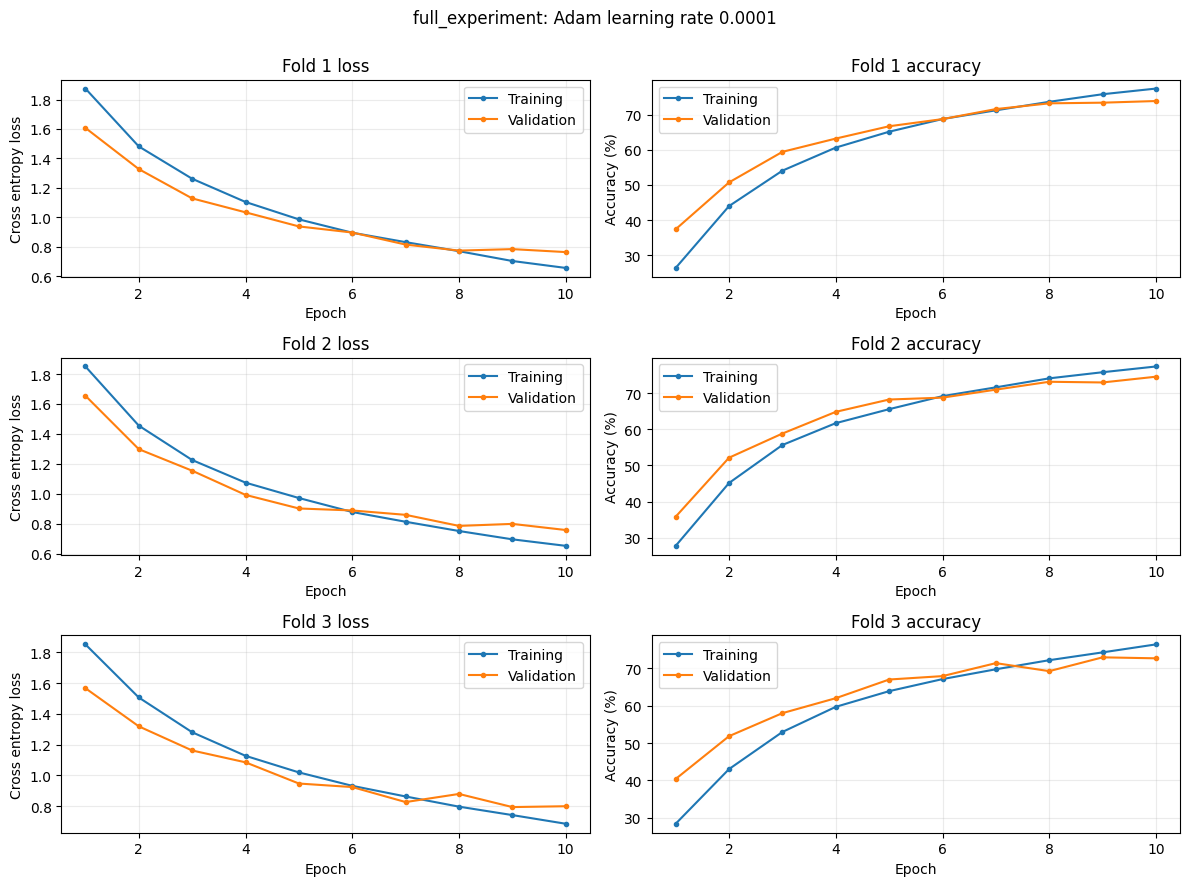

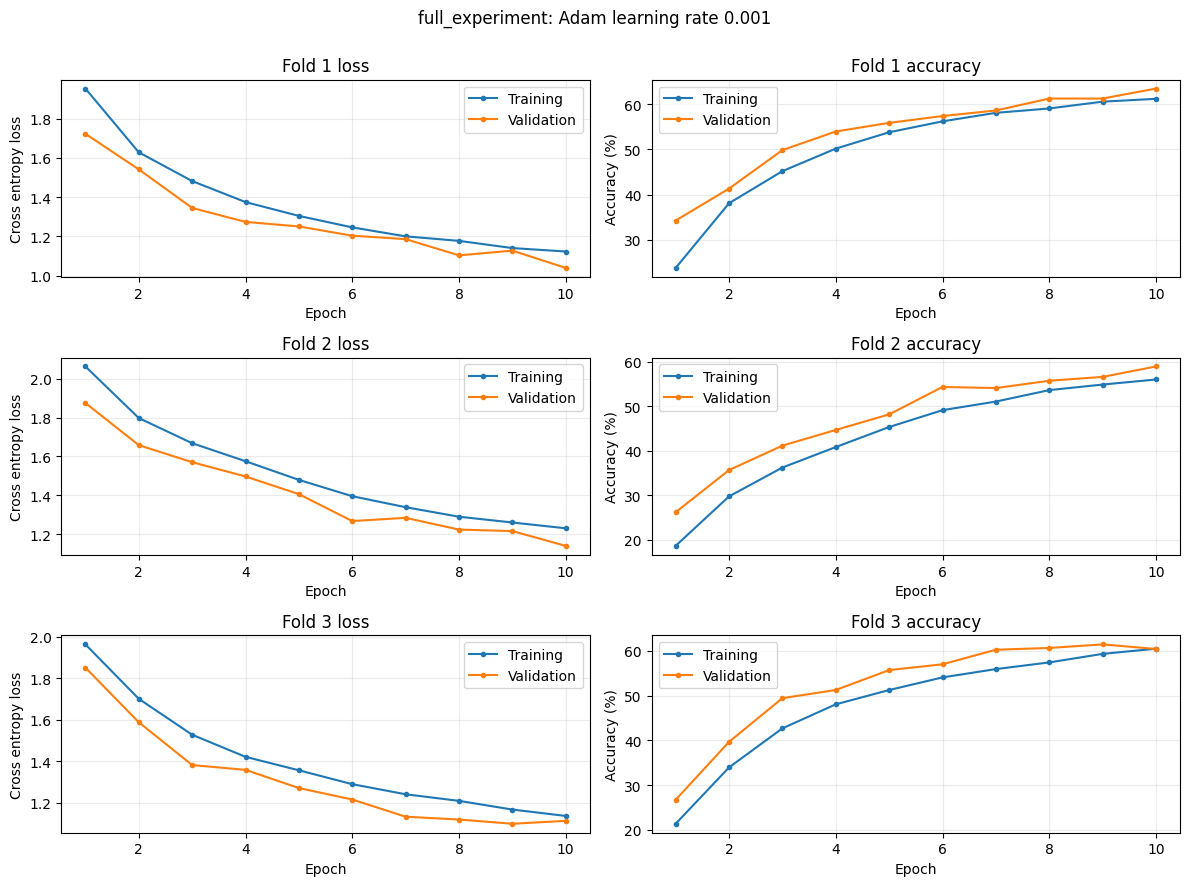

In [9]:
# Summarise the validation results across folds
comparison = []  # Build a summary table with one row per learning rate.

# Process one learning-rate setting at a time
for learning_rate in LEARNING_RATES:  # Aggregate the same three folds for each setting.
    rows = [row for row in cv_results if row["learning_rate"] == learning_rate]  # Select matching fold results.
    scores = np.array([row["final_val_accuracy"] for row in rows])  # Gather fixed-budget fold accuracies.
    comparison.append(dict(learning_rate=learning_rate, mean_accuracy=float(scores.mean()),  # Record this setting and its mean final-epoch accuracy across folds.
                           sample_sd=float(scores.std(ddof=1)),  # Measure fold variation using the sample standard deviation, rather than a confidence interval.
                           mean_loss=float(np.mean([row["final_val_loss"] for row in rows]))))  # Summarise accuracy, variation and loss.
    print(f"lr={learning_rate:g}: mean validation accuracy {scores.mean():.2%}, sample SD {scores.std(ddof=1):.2%}")  # Report variation in accuracy units.

# Save the learning-rate comparison table
with (run_dir / "comparison.csv").open("w", newline="", encoding="utf-8") as handle:  # Save the report comparison table.
    writer = csv.DictWriter(handle, fieldnames=list(comparison[0]))  # Name the summary columns.
    writer.writeheader()  # Write column headings.
    writer.writerows(comparison)  # Write measured settings and their aggregated metrics.

# Select settings only from a completed full experiment
selected_learning_rate = None  # Do not select a final setting from short-check metrics.
if not QUICK_CHECK:  # Only completed full-data runs support model selection.
    selected_learning_rate = max(comparison, key=lambda row: row["mean_accuracy"])["learning_rate"]  # Choose the highest mean final-epoch validation accuracy.
    print(f"Selected learning rate from full cross-validation: {selected_learning_rate:g}")  # Identify the selection criterion and result.
else:  # Keep quick-check results clearly distinguished.
    print("QUICK CHECK ONLY: do not report these scores or use them to select the final model.")  # Explain the limited purpose of this execution.

# Process one learning-rate setting at a time
for learning_rate in LEARNING_RATES:  # Save a complete set of curves for each setting.

    # Create the loss and accuracy graphs for this setting
    fig, axes = plt.subplots(FOLDS, 2, figsize=(12, 3 * FOLDS), squeeze=False)  # Give each fold a loss plot and an accuracy plot.
    histories = [item for item in all_histories if item["learning_rate"] == learning_rate]  # Select this setting's fold histories.

    # Draw a separate pair of graphs for every fold
    for row, item in enumerate(histories):  # Draw the measured curves fold by fold.
        epochs = [point["epoch"] for point in item["history"]]  # Read epoch numbers.
        for split, label in [("train", "Training"), ("val", "Validation")]:  # Draw both sides of the split.
            axes[row, 0].plot(epochs, [point[f"{split}_loss"] for point in item["history"]], marker=".", label=label)  # Plot mean loss.
            axes[row, 1].plot(epochs, [100*point[f"{split}_accuracy"] for point in item["history"]], marker=".", label=label)  # Plot accuracy percent.

        # Label and format the graphs
        axes[row, 0].set(title=f"Fold {item['fold']} loss", xlabel="Epoch", ylabel="Cross entropy loss")  # Label the first graph.
        axes[row, 1].set(title=f"Fold {item['fold']} accuracy", xlabel="Epoch", ylabel="Accuracy (%)")  # Label the second graph.
        for axis in axes[row]:  # Format both graphs consistently.
            axis.legend()  # Label the curves.
            axis.grid(alpha=0.25)  # Help readers estimate values.

    # Display and save the complete figure
    fig.suptitle(f"{mode_name}: Adam learning rate {learning_rate:g}")  # Identify the experiment and whether it is only a check.
    fig.tight_layout(rect=(0, 0, 1, 0.98))  # Reserve space for the main title.
    fig.savefig(run_dir / f"lr_{learning_rate:g}_curves.png", dpi=200)  # Save the figure for analysis.
    plt.show()  # Display the fold curves.
    plt.close(fig)  # Release plot memory.


Additional Experiment Effect of Data Augmentation (Jakub)

For this experiment I compare training with and without data augmentation. The earlier experiment used random horizontal flips and rotations of up to 20 degrees. The new runs remove these operations, while still converting images to tensors and normalising them.

To make the comparison fair, I keep the other settings the same:
- Adam optimiser with a learning rate of 0.0001
- Three stratified folds
- Ten epochs per fold
- Batch size of 32
- The same VGG11-style architecture
- Matching starting seeds
- The same normalisation values, calculated from each fold's training images

Each fold starts with a new model and optimiser. I compare validation accuracy at epoch 10, the mean and standard deviation across folds, and the training and validation curves. This lets me investigate how augmentation affects learning and performance on held-out images under the chosen training budget.

The new results are saved separately so the earlier results and trained model are preserved. The test set is not used in this experiment. After comparing the validation results, I will choose the final augmentation setting before evaluating the selected model on the test set.

Resources:

- Torchvision — RandomHorizontalFlip:
  https://docs.pytorch.org/vision/0.25/generated/torchvision.transforms.RandomHorizontalFlip.html
  

In [10]:
# Import the utilities used by this additional experiment.
import copy  # Make independent dataset views without changing Mateusz's dataset objects.
import csv  # Save fold results and the augmentation comparison.
import json  # Read baseline histories and save the new measurements.
import time  # Measure epoch duration.
from datetime import datetime  # Give the additional experiment a unique directory.
from pathlib import Path  # Construct paths without relying on the current working directory.
import numpy as np  # Summarise fold results.
import matplotlib.pyplot as plt  # Plot augmented and non-augmented learning curves.
import torch  # Create model tensors, optimisers and checkpoints.
import torch.nn as nn  # Use cross-entropy loss.
import torchvision.transforms as transform  # Convert and normalise images without augmentation.
from torch.utils.data import Subset, DataLoader  # Create fold-specific batches.
from sklearn.model_selection import StratifiedKFold  # Recreate the original stratified fold membership.


# Reopen the completed augmented baseline without modifying its settings.
noaug_baseline_dir = Path(run_dir)  # Reuse the baseline folder created earlier in this notebook.
assert (noaug_baseline_dir / "comparison.csv").is_file()  # Require the completed baseline.
noaug_original_settings = json.loads((noaug_baseline_dir / "settings.json").read_text(encoding="utf-8"))  # Read the original setup.
noaug_fold_statistics = json.loads((noaug_baseline_dir / "fold_preprocessing.json").read_text(encoding="utf-8"))  # Reuse identical training-only fitted RGB statistics.


# Use the same fixed training budget and split configuration as the baseline.
noaug_epochs = int(noaug_original_settings["epochs"])  # Restore ten epochs per fold.
noaug_folds = int(noaug_original_settings["folds"])  # Restore three folds.
noaug_batch_size = int(noaug_original_settings["batch_size"])  # Restore batches of 32.
noaug_seed = int(noaug_original_settings["seed"])  # Restore the original base seed.
noaug_learning_rate = 0.0001  # Hold the previously selected learning rate fixed.
assert not noaug_original_settings["quick_check"]  # Require real full-data baseline results.
assert noaug_epochs == 10 and noaug_folds == 3  # Check that this comparison matches the agreed experiment.

# Use the device selected by the main notebook.
if str(device).startswith("cpu"):  # Keep the experiment runnable on laptops without a supported GPU.
    print("Running on CPU: this experiment may take substantially longer than the recorded GPU runs.")  # Explain the runtime difference without preventing execution.
assert len(training_full) == len(validation_full) == 50000  # Split full development data rather than old subsets.
assert training_full.targets == validation_full.targets  # Require matching raw sample order in both dataset views.


# Create an independent results directory; leave run_dir and final_model untouched.
noaug_dir = noaug_baseline_dir.parent / f"no_augmentation_{datetime.now():%Y%m%d_%H%M%S_%f}"  # Separate the new experiment from all earlier runs.
noaug_dir.mkdir(parents=True, exist_ok=False)  # Prevent silent replacement of an existing experiment.
noaug_config = dict(  # Record the settings needed to describe and reproduce the extra experiment.
    baseline_directory=str(noaug_baseline_dir), augmentation=False,  # Identify the source baseline and the changed factor.
    learning_rate=noaug_learning_rate, epochs=noaug_epochs, folds=noaug_folds,  # Save the fixed learning rate and budget.
    batch_size=noaug_batch_size, seed=noaug_seed, optimizer="Adam", weight_decay=0,  # Preserve the remaining training choices.
    selection_metric="mean final-epoch validation accuracy", device=str(device),  # State the same comparison metric as the baseline.
    torch_version=str(torch.__version__),  # Record the software version used for these runs.
)  # Complete the configuration record.
(noaug_dir / "settings.json").write_text(json.dumps(noaug_config, indent=2), encoding="utf-8")  # Save the additional experiment setup.
(noaug_dir / "fold_preprocessing.json").write_text(json.dumps(noaug_fold_statistics, indent=2), encoding="utf-8")  # Preserve the exact reused preprocessing statistics.


# Recreate fold membership from the same labels, fold count and split seed.
noaug_targets = np.asarray(training_full.targets)  # Use only development labels for stratification.
noaug_splitter = StratifiedKFold(n_splits=noaug_folds, shuffle=True, random_state=noaug_seed)  # Match the original splitting rule.
noaug_splits = list(noaug_splitter.split(np.zeros(len(noaug_targets)), noaug_targets))  # Fix the fold indices before training.
print(f"No-augmentation experiment: {noaug_folds} folds, {noaug_epochs} epochs, lr={noaug_learning_rate}, device={device}")  # Confirm the configuration.
print(f"New results folder: {noaug_dir}")  # Show where the new files will be saved.


No-augmentation experiment: 3 folds, 10 epochs, lr=0.0001, device=cuda
New results folder: cnn_results\no_augmentation_20261028_214204_010436


Train Without Augmentation

For this experiment I train a fresh model for each of the three folds without applying random flips or rotations. Training images are still converted to tensors and normalised, and validation preprocessing stays the same.

Removing both augmentation methods together lets me compare training with augmentation against training without it. This experiment does not measure the separate effects of flipping and rotation.

The existing final model and its results are preserved. I will compare the validation results before choosing the final augmentation setting and running test evaluation.

Resources: Resetting seeds before training fresh fold models.
* PyTorch — Reproducibility:
  https://docs.pytorch.org/docs/2.10/notes/randomness.html
  

In [11]:
# Prepare independent result containers for the new comparison.
noaug_results = []  # Keep one final validation result for each fold.
noaug_histories = []  # Keep complete histories for learning-curve analysis.
noaug_criterion = nn.CrossEntropyLoss()  # Retain the original classification objective.


# Train one fresh model for each rotating validation fold.
for noaug_fold, (noaug_train_indices, noaug_val_indices) in enumerate(noaug_splits, start=1):  # Use the same three development splits as the baseline.

    # Reset the corresponding fold's initialisation and random-number generators.
    seed_everything(noaug_seed + noaug_fold)  # Match the seed used for this fold in the augmented experiment.
    noaug_stats = noaug_fold_statistics[noaug_fold - 1]  # Retrieve statistics fitted to this fold's training images only.

    # Remove augmentation while keeping conversion and normalisation.
    noaug_transform = transform.Compose([  # Create a deterministic image pipeline for the controlled experiment.
        transform.ToTensor(),  # Convert images to channel-first floating-point tensors in [0, 1].
        transform.Normalize(noaug_stats["mean"], noaug_stats["std"]),  # Apply the same fitted values as the corresponding baseline fold.
    ])  # No random flip or random rotation is present.
    noaug_training_view = copy.copy(training_full)  # Keep the original development dataset unchanged.
    noaug_validation_view = copy.copy(validation_full)  # Keep validation transforms independent from other views.
    noaug_training_view.transform = noaug_transform  # Train on unaugmented, normalised images.
    noaug_validation_view.transform = noaug_transform  # Validate using the unchanged deterministic preprocessing.

    # Build loaders for the same fold membership and batch size.
    noaug_training_load = DataLoader(Subset(noaug_training_view, noaug_train_indices.tolist()), batch_size=noaug_batch_size, shuffle=True)  # Shuffle this fold's training images.
    noaug_validation_load = DataLoader(Subset(noaug_validation_view, noaug_val_indices.tolist()), batch_size=noaug_batch_size, shuffle=False)  # Read all validation images in order.

    # Create a fresh model and optimiser without replacing the trained final model.
    noaug_model = VGG11().to(device)  # Use the original architecture with matching seeded initial weights.
    noaug_optimizer = torch.optim.Adam(noaug_model.parameters(), lr=noaug_learning_rate)  # Reset Adam state and retain its original defaults.
    noaug_history = []  # Start a separate epoch history for this fold.
    noaug_best_loss = float("inf")  # Reset best-checkpoint tracking.
    noaug_best_epoch = 0  # Record the epoch with lowest validation loss.

    # Use the same fixed epoch budget without the quick-check batch limit.
    for noaug_epoch in range(1, noaug_epochs + 1):  # Perform ten complete training passes per fold.
        noaug_start = time.perf_counter()  # Time training plus validation.
        noaug_train_loss, noaug_train_acc = run_epoch(noaug_model, noaug_training_load, noaug_criterion, noaug_optimizer)  # Learn from all training batches.
        noaug_val_loss, noaug_val_acc = run_epoch(noaug_model, noaug_validation_load, noaug_criterion)  # Validate without gradients or dropout.

        # Store observed metrics for every epoch.
        noaug_history.append(dict(  # Save the full learning history rather than only the last result.
            epoch=noaug_epoch, train_loss=noaug_train_loss, train_accuracy=noaug_train_acc,  # Record training measurements.
            val_loss=noaug_val_loss, val_accuracy=noaug_val_acc, seconds=time.perf_counter()-noaug_start,  # Record validation measurements and runtime.
        ))  # Add this completed epoch to the fold history.

        # Preserve lowest-loss weights as a diagnostic, while comparing final-epoch metrics later.
        if noaug_val_loss < noaug_best_loss:  # Check whether validation loss improved.
            noaug_best_loss, noaug_best_epoch = noaug_val_loss, noaug_epoch  # Remember the selected checkpoint.
            torch.save(noaug_model.state_dict(), noaug_dir / f"fold_{noaug_fold}_best_weights.pt")  # Save in the new experiment folder only.

        # Save progress and display the epoch result.
        (noaug_dir / f"fold_{noaug_fold}_history.json").write_text(json.dumps(noaug_history, indent=2), encoding="utf-8")  # Preserve measurements after every epoch.
        print(  # Show fold progress and the measured training/validation values.
            f"no_augmentation | fold={noaug_fold}/{noaug_folds} epoch={noaug_epoch}/{noaug_epochs} | "  # Identify the current run.
            f"train loss={noaug_train_loss:.4f} acc={noaug_train_acc:.2%} | "  # Show training metrics.
            f"val loss={noaug_val_loss:.4f} acc={noaug_val_acc:.2%} | {noaug_history[-1]['seconds']:.1f}s"  # Show validation metrics and duration.
        )  # Finish the progress line.

    # Record the final-epoch result using the baseline comparison rule.
    noaug_results.append(dict(  # Keep one summary per fold.
        learning_rate=noaug_learning_rate, fold=noaug_fold, final_val_loss=noaug_val_loss,  # Record the setting and final loss.
        final_val_accuracy=noaug_val_acc, best_val_loss=noaug_best_loss, best_epoch=noaug_best_epoch,  # Keep final accuracy separate from checkpoint diagnostics.
    ))  # Complete this fold's result record.
    noaug_histories.append(noaug_history)  # Preserve the history for plotting.
    with (noaug_dir / "fold_results.csv").open("w", newline="", encoding="utf-8") as noaug_handle:  # Save every completed fold.
        noaug_writer = csv.DictWriter(noaug_handle, fieldnames=list(noaug_results[0]))  # Name the metric columns.
        noaug_writer.writeheader()  # Write column headings.
        noaug_writer.writerows(noaug_results)  # Write all completed fold summaries.

    # Release fold resources while preserving the original augmented final model.
    del noaug_optimizer, noaug_model  # Remove only this experiment's fold model and optimiser.
    if torch.cuda.is_available():  # Support CPU-only environments as well as NVIDIA GPU environments.
        torch.cuda.empty_cache()  # Release unused cached CUDA memory when a GPU is available.


no_augmentation | fold=1/3 epoch=1/10 | train loss=1.7978 acc=28.91% | val loss=1.5781 acc=39.47% | 33.0s
no_augmentation | fold=1/3 epoch=2/10 | train loss=1.3249 acc=50.68% | val loss=1.1659 acc=57.54% | 32.5s
no_augmentation | fold=1/3 epoch=3/10 | train loss=1.0464 acc=61.97% | val loss=1.0567 acc=62.73% | 32.5s
no_augmentation | fold=1/3 epoch=4/10 | train loss=0.8464 acc=69.80% | val loss=0.8949 acc=68.30% | 32.5s
no_augmentation | fold=1/3 epoch=5/10 | train loss=0.6742 acc=76.34% | val loss=0.8762 acc=70.23% | 32.5s
no_augmentation | fold=1/3 epoch=6/10 | train loss=0.5126 acc=82.21% | val loss=0.9512 acc=68.90% | 32.8s
no_augmentation | fold=1/3 epoch=7/10 | train loss=0.3805 acc=86.95% | val loss=0.9113 acc=72.33% | 34.1s
no_augmentation | fold=1/3 epoch=8/10 | train loss=0.2787 acc=90.38% | val loss=1.0022 acc=72.26% | 33.4s
no_augmentation | fold=1/3 epoch=9/10 | train loss=0.1999 acc=93.38% | val loss=1.1657 acc=72.12% | 34.0s
no_augmentation | fold=1/3 epoch=10/10 | train

Compare Augmentation Settings

For this section I compare training with and without augmentation using validation results at epoch 10 for each fold.

The comparison includes:
- Mean validation accuracy: shows average performance across the three folds
- Sample standard deviation: shows how much the results vary between folds
- Individual fold scores: show whether one setting performs better consistently
- Learning curves: show how training and validation performance change over time

The standard deviation describes variation between folds; it is not a confidence interval. A small difference in mean accuracy should be interpreted carefully because the comparison uses only three folds.

I use these validation results to choose the final augmentation setting. If I keep augmentation, I can use the final model already trained. If I choose no augmentation, I will train a fresh model on all 50,000 development images without random flips or rotations.

After this decision, I evaluate the chosen model on the separate test set using the normalisation values calculated from its training data.

With augmentation: mean validation accuracy 73.69%, sample SD 0.94%, mean loss 0.7736
Without augmentation: mean validation accuracy 72.46%, sample SD 0.39%, mean loss 1.1263


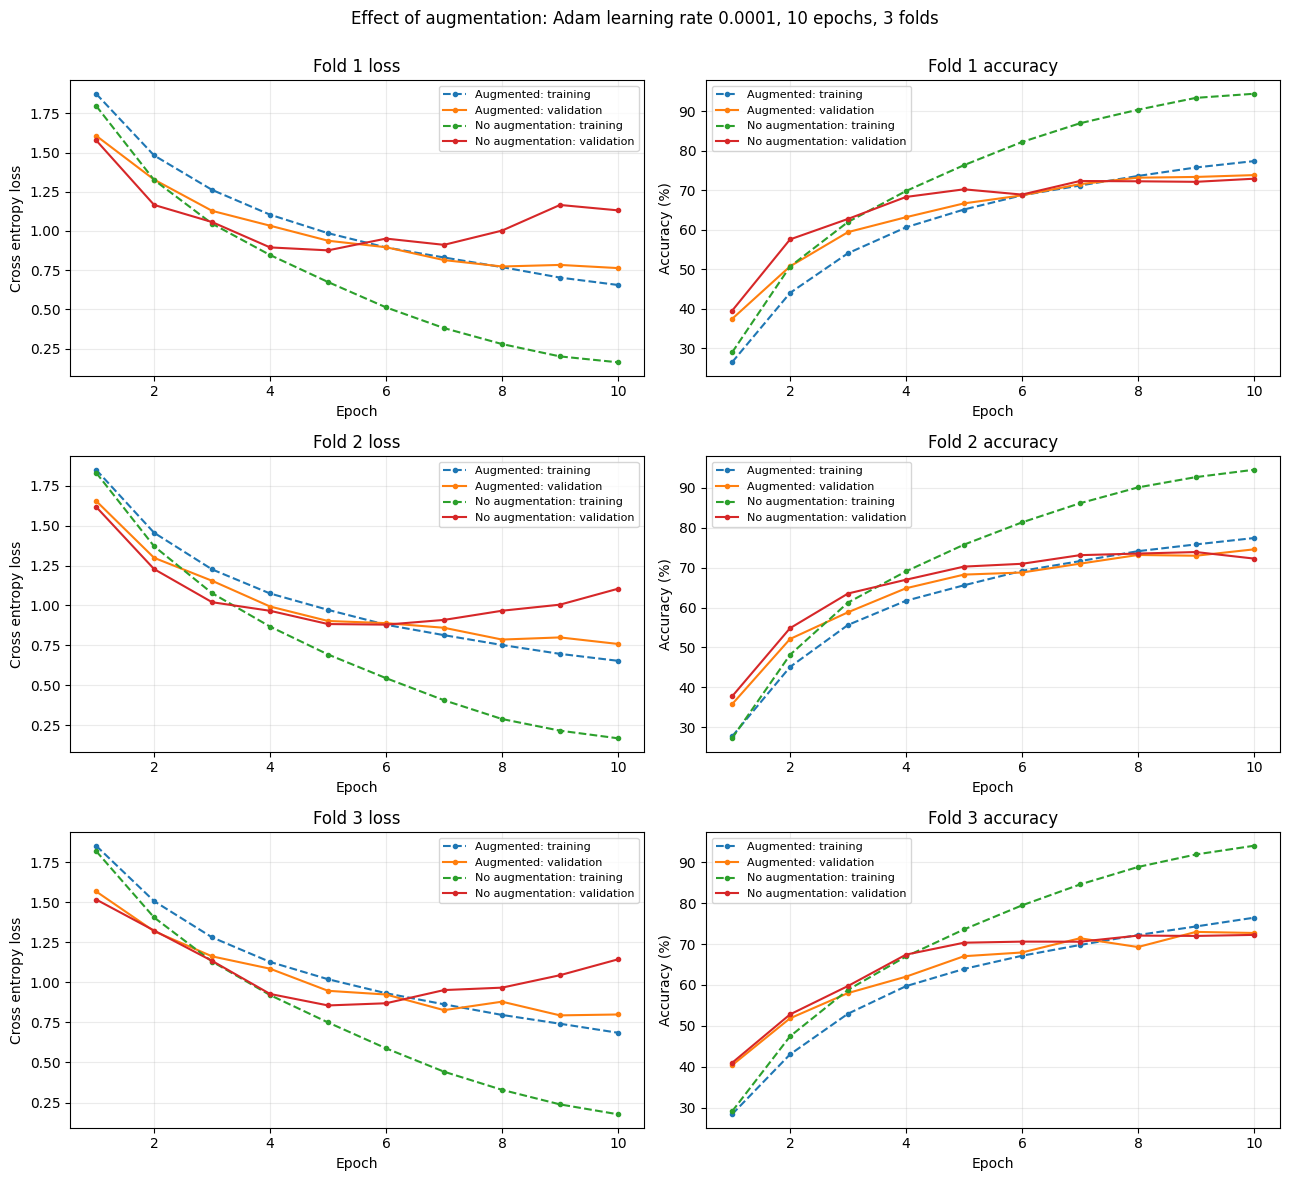

Comparison saved. Review validation evidence before running final test evaluation.
Saved files: cnn_results\no_augmentation_20261028_214204_010436


In [12]:
# Read matching augmented baseline histories directly from the saved results.
noaug_baseline_histories = []  # Keep the matching learning-rate baseline for each fold.
for noaug_fold in range(1, noaug_folds + 1):  # Read all three completed baseline folds.
    noaug_baseline_path = noaug_baseline_dir / f"lr_{noaug_learning_rate:g}" / f"fold_{noaug_fold}_history.json"  # Select the correct learning-rate history.
    noaug_baseline_histories.append(json.loads(noaug_baseline_path.read_text(encoding="utf-8")))  # Restore actual baseline measurements.

# NEW: reject incomplete histories before comparing final-epoch scores.
for baseline_history in noaug_baseline_histories:

    assert [
        entry["epoch"] for entry in baseline_history
    ] == list(range(1, noaug_epochs + 1)), "Incomplete baseline history."

# Compare scores at the same final epoch budget.
noaug_comparison = []  # Build one summary per augmentation setting.
for noaug_label, noaug_setting_histories in [("With augmentation", noaug_baseline_histories), ("Without augmentation", noaug_histories)]:  # Compare both conditions.
    noaug_scores = np.array([noaug_h[-1]["val_accuracy"] for noaug_h in noaug_setting_histories])  # Use final-epoch accuracy for each fold.
    noaug_losses = np.array([noaug_h[-1]["val_loss"] for noaug_h in noaug_setting_histories])  # Use matching final-epoch validation losses.
    noaug_comparison.append(dict(  # Save an aggregate record with the underlying fold scores.
        augmentation=noaug_label, mean_accuracy=float(noaug_scores.mean()), sample_sd=float(noaug_scores.std(ddof=1)),  # Record mean accuracy and fold variation.
        mean_loss=float(noaug_losses.mean()), fold_1=float(noaug_scores[0]), fold_2=float(noaug_scores[1]), fold_3=float(noaug_scores[2]),  # Preserve the individual scores.
    ))  # Complete this setting's comparison record.
    print(f"{noaug_label}: mean validation accuracy {noaug_scores.mean():.2%}, sample SD {noaug_scores.std(ddof=1):.2%}, mean loss {noaug_losses.mean():.4f}")  # Display observed aggregate performance.


# Save the comparison separately from the learning-rate experiment.
with (noaug_dir / "augmentation_comparison.csv").open("w", newline="", encoding="utf-8") as noaug_handle:  # Create a report-ready comparison table.
    noaug_writer = csv.DictWriter(noaug_handle, fieldnames=list(noaug_comparison[0]))  # Use explicit metric columns.
    noaug_writer.writeheader()  # Write the table headings.
    noaug_writer.writerows(noaug_comparison)  # Write both measured conditions.
(noaug_dir / "augmentation_comparison.json").write_text(json.dumps(noaug_comparison, indent=2), encoding="utf-8")  # Save a machine-readable version too.


# Plot training and validation curves for both conditions in every fold.
noaug_fig, noaug_axes = plt.subplots(noaug_folds, 2, figsize=(13, 4*noaug_folds), squeeze=False)  # Create paired loss/accuracy panels.
for noaug_row in range(noaug_folds):  # Draw one row per fold.
    for noaug_label, noaug_h in [("Augmented", noaug_baseline_histories[noaug_row]), ("No augmentation", noaug_histories[noaug_row])]:  # Overlay the two conditions.
        noaug_x = [noaug_point["epoch"] for noaug_point in noaug_h]  # Use the recorded epoch numbers.
        for noaug_split, noaug_split_label, noaug_style in [("train", "training", "--"), ("val", "validation", "-")]:  # Distinguish training from validation visually.
            noaug_curve_label = f"{noaug_label}: {noaug_split_label}"  # Name this curve accurately.
            noaug_axes[noaug_row, 0].plot(noaug_x, [noaug_point[f"{noaug_split}_loss"] for noaug_point in noaug_h], linestyle=noaug_style, marker=".", label=noaug_curve_label)  # Plot mean loss.
            noaug_axes[noaug_row, 1].plot(noaug_x, [100*noaug_point[f"{noaug_split}_accuracy"] for noaug_point in noaug_h], linestyle=noaug_style, marker=".", label=noaug_curve_label)  # Plot percentage accuracy.
    noaug_axes[noaug_row, 0].set(title=f"Fold {noaug_row+1} loss", xlabel="Epoch", ylabel="Cross entropy loss")  # Label the loss graph.
    noaug_axes[noaug_row, 1].set(title=f"Fold {noaug_row+1} accuracy", xlabel="Epoch", ylabel="Accuracy (%)")  # Label the accuracy graph.
    for noaug_axis in noaug_axes[noaug_row]:  # Format both panels consistently.
        noaug_axis.legend(fontsize=8)  # Identify all four curves.
        noaug_axis.grid(alpha=0.25)  # Make values easier to compare.
noaug_fig.suptitle("Effect of augmentation: Adam learning rate 0.0001, 10 epochs, 3 folds")  # State the fixed experimental setting.
noaug_fig.tight_layout(rect=(0, 0, 1, 0.98))  # Reserve space for the figure title.
noaug_fig.savefig(noaug_dir / "augmentation_comparison_curves.png", dpi=200)  # Save the complete comparison figure.
plt.show()  # Display the plots in the notebook for saving with outputs.
plt.close(noaug_fig)  # Release plotting memory.
print("Comparison saved. Review validation evidence before running final test evaluation.")  # Leave the final choice explicit.
print(f"Saved files: {noaug_dir}")  # Identify the additional experiment's folder.


STEP 4: Train the Final Model and Evaluate It (Jakub)

For this part I train a fresh model using all 50,000 development images. The model uses the learning rate selected from the cross-validation results and trains for ten epochs. It starts with new weights rather than continuing from one of the fold models.

There is no separate validation set during this final training stage because the settings have already been chosen using cross-validation. The weights are saved after the final epoch. The separate 10,000 test images are not used to choose the training settings.

The final evaluation includes:
- Cross-entropy loss: measures classification error on the test images
- Accuracy: shows the proportion of test images classified correctly
- Precision: measures how often predictions for each class are correct
- Recall: measures how many images belonging to each class are correctly identified
- F1 score: combines precision and recall for each class
- Macro averages: average the class scores, giving each class equal importance
- Confusion matrix: shows which classes the model commonly mixes up

If the model never predicts a particular class, its precision is recorded as zero.

The test-evaluation cell is run after the learning rate, epoch budget and augmentation setting have been fixed. This keeps the test set separate from model selection and provides a final check of performance on images that were not used for training.

In [13]:
# Change the next line only after reviewing a completed full-data cross-validation comparison.
# Keep final training and testing separate from experimentation
RUN_FINAL_EVALUATION = True  # Set True when your full experiment's settings and budget are fixed.

# Prevent test evaluation from using an unfinished model
final_ready = False  # Prevent evaluation from accidentally using an earlier model.
if RUN_FINAL_EVALUATION and QUICK_CHECK:  # A smoke test does not establish a final training configuration.
    raise ValueError("Complete full cross-validation with QUICK_CHECK=False before final training.")  # Explain the required prerequisite.

# Refit only after choosing settings from full cross-validation
if RUN_FINAL_EVALUATION and selected_learning_rate is not None:  # Start the final refit only after full-data selection.
    seed_everything(SEED + 1000)  # Give the independent final model a documented fresh seed.

    # Fit final preprocessing using all development images
    final_indices = np.arange(len(training_full))  # Use all development images for the final training run.
    final_mean, final_std = channel_statistics(training_full.data, final_indices)  # Fit preprocessing without using test images.
    final_training_transform, final_evaluation_transform = make_transforms(final_mean, final_std)  # Create final training/test transforms.

    # Prepare the complete development dataset for training
    final_training_view = copy.copy(training_full)  # Keep the original raw dataset available.
    final_training_view.transform = final_training_transform  # Apply training augmentation and final fitted statistics.
    final_training_load = DataLoader(final_training_view, batch_size=BATCH_SIZE, shuffle=True)  # Shuffle all 50,000 training images.

    # Create an independent final model with fresh weights
    final_model = VGG11().to(device)  # Reinitialise the architecture rather than reusing fold weights.
    final_optimizer = torch.optim.Adam(final_model.parameters(), lr=selected_learning_rate)  # Use the selected setting with fresh optimiser state.
    final_history = []  # Record final training metrics without inventing validation results.
    final_epochs = EPOCHS  # Use the fixed budget already investigated in cross-validation.

    # Train for the predetermined final epoch budget
    for epoch in range(1, final_epochs + 1):  # Train for the predetermined number of full passes.
        start = time.perf_counter()  # Time final training.
        loss, accuracy = run_epoch(final_model, final_training_load, criterion, final_optimizer)  # Learn from all development images.
        final_history.append(dict(epoch=epoch, train_loss=loss, train_accuracy=accuracy, seconds=time.perf_counter()-start))  # Store actual final-run metrics.
        (run_dir / "final_training_history.json").write_text(json.dumps(final_history, indent=2), encoding="utf-8")  # Save progress each epoch.
        print(f"Final training epoch {epoch}/{final_epochs}: loss={loss:.4f}, accuracy={accuracy:.2%}")  # Show progress without accessing test data.

    # Save final weights and the settings needed for inference
    torch.save(final_model.state_dict(), run_dir / "final_model_weights.pt")  # Save weights at the predetermined final epoch.
    final_config = dict(learning_rate=selected_learning_rate, epochs=final_epochs, seed=SEED+1000,  # Record the chosen learning rate, final epoch budget and final-model seed.
                        mean=final_mean, std=final_std, classes=classes, input_shape=[3, 32, 32],  # Save final normalisation values, class ordering and expected image dimensions.
                        optimizer="Adam", batch_size=BATCH_SIZE, parameter_count=sum(parameter.numel() for parameter in final_model.parameters()))  # Preserve settings needed for inference.
    (run_dir / "final_model_config.json").write_text(json.dumps(final_config, indent=2), encoding="utf-8")  # Save fitted preprocessing with the model.

    # Finish training and prepare the model for inference
    del final_optimizer  # Release Adam state before evaluation.
    final_model.eval()  # Disable dropout for final inference.
    final_ready = True  # Mark successful completion of the final training stage.
else:  # Let a normal cross-validation-only run finish without launching final training.
    print("Final training skipped. Review full cross-validation before enabling RUN_FINAL_EVALUATION above.")  # State the pending stage.


Final training epoch 1/10: loss=1.7354, accuracy=32.48%
Final training epoch 2/10: loss=1.2995, accuracy=52.51%
Final training epoch 3/10: loss=1.0706, accuracy=61.91%
Final training epoch 4/10: loss=0.9292, accuracy=67.53%
Final training epoch 5/10: loss=0.8333, accuracy=71.05%
Final training epoch 6/10: loss=0.7529, accuracy=73.96%
Final training epoch 7/10: loss=0.6917, accuracy=76.23%
Final training epoch 8/10: loss=0.6372, accuracy=78.18%
Final training epoch 9/10: loss=0.5846, accuracy=80.25%
Final training epoch 10/10: loss=0.5469, accuracy=81.36%


Final Model Selection and Test Evaluation

I used the cross-validation results to choose the final training settings before evaluating the model on the test set.

First, I compared Adam learning rates of 0.0001 and 0.001 using three folds and ten epochs per fold. The learning rate of 0.0001 achieved a mean validation accuracy of 73.69%, compared with 60.92% for 0.001. It performed better in every fold, so I selected 0.0001.

I then compared training with and without random horizontal flips and rotations. With augmentation, mean validation accuracy was 73.69%, compared with 72.46% without augmentation. Without augmentation, training accuracy reached approximately 94%, while validation accuracy remained around 72% and validation loss increased in later epochs. These results suggest greater overfitting without augmentation under the chosen training budget.

Based on these comparisons, I kept augmentation and selected:
- Optimiser: Adam
- Learning rate: 0.0001
- Training duration: ten epochs
- Batch size: 32
- Training augmentation: random horizontal flips and rotations up to 20 degrees

A fresh final model was trained on all 50,000 development images using these settings. Its final training accuracy was 81.36%; this is separate from its test accuracy.

The following cell trains the final model. The subsequent test-evaluation cell assesses it on the separate 10,000 test images.

The evaluation calculates test loss, accuracy, per-class precision, recall and F1, macro averages, and a confusion matrix. The test set was not used to choose the learning rate, augmentation setting or epoch budget.

This submission reproduces the selected augmented configuration. Final training retains random flips and rotations following the recorded validation comparison.

Test images=10000; loss=0.6470; accuracy=78.24%
Macro precision=0.788; recall=0.782; F1=0.783
airplane     precision=0.858 recall=0.777 F1=0.815
automobile   precision=0.902 recall=0.887 F1=0.895
bird         precision=0.667 recall=0.744 F1=0.704
cat          precision=0.576 recall=0.627 F1=0.601
deer         precision=0.778 recall=0.740 F1=0.759
dog          precision=0.717 recall=0.659 F1=0.687
frog         precision=0.768 recall=0.888 F1=0.824
horse        precision=0.891 recall=0.757 F1=0.818
ship         precision=0.855 recall=0.898 F1=0.876
truck        precision=0.863 recall=0.847 F1=0.855


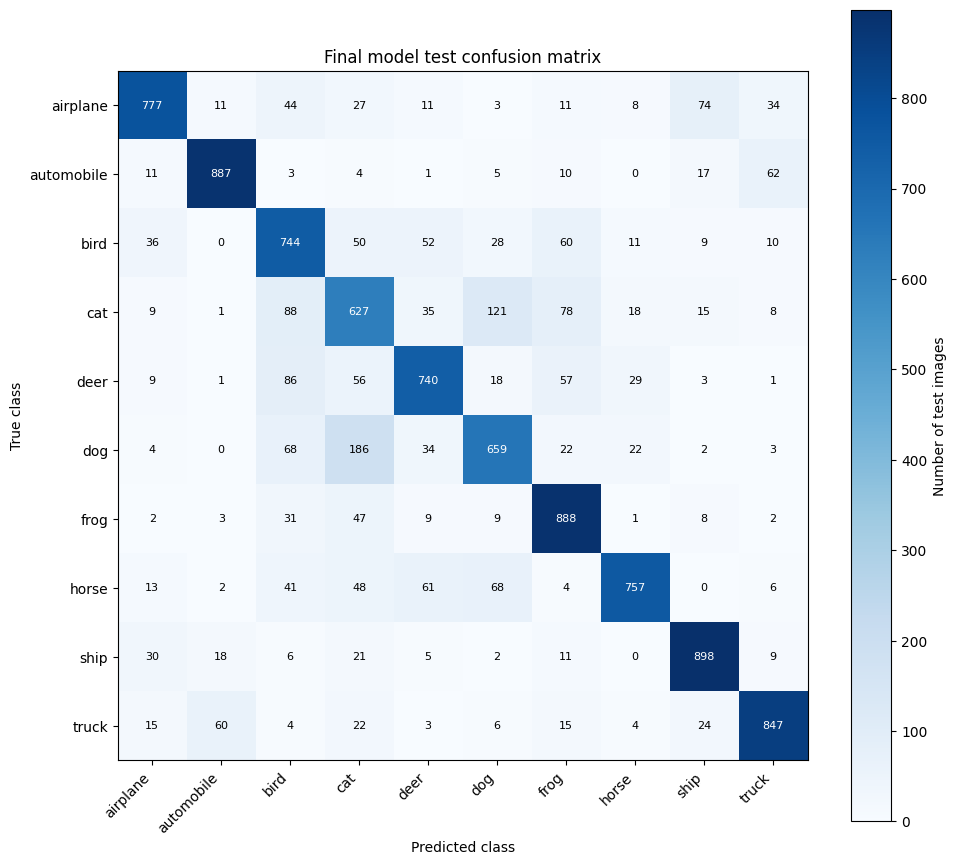

In [14]:
# Calculate per-class precision, recall, F1 and support from a confusion matrix.
# Rows represent true classes and columns represent predicted classes.
# Use zero for a metric whose denominator is zero, avoiding invalid numbers.
# Returns one array for each metric and an array of actual class counts.
def metrics_from_confusion(confusion):  # Calculate class metrics from row=true, column=predicted counts.

    # Read correct predictions and the relevant class totals
    true_positive = np.diag(confusion).astype(float)  # Correct predictions lie on the diagonal.
    predicted_count = confusion.sum(axis=0)  # Count predictions made for each class.
    support = confusion.sum(axis=1)  # Count actual examples belonging to each class.

    # Calculate precision, recall and F1 with safe division
    precision = np.divide(true_positive, predicted_count, out=np.zeros_like(true_positive), where=predicted_count != 0)  # Use precision zero if no positives were predicted.
    recall = np.divide(true_positive, support, out=np.zeros_like(true_positive), where=support != 0)  # Use recall zero for an absent class.
    denominator = precision + recall  # Form the denominator of the harmonic mean.
    f1 = np.divide(2*precision*recall, denominator, out=np.zeros_like(true_positive), where=denominator != 0)  # Use F1 zero if both component metrics are zero.

    return precision, recall, f1, support  # Return values for printing and saving.

# Evaluate only a successfully trained final model
if final_ready:  # Require a completed independent final training run before test evaluation.
    final_test_view = copy.copy(test_set)  # Keep official test images separate from development views.
    final_test_view.transform = final_evaluation_transform  # Use statistics fitted only to development images.
    test_load = DataLoader(final_test_view, batch_size=BATCH_SIZE, shuffle=False)  # Evaluate each test image exactly once.

    # Prepare counters for the test metrics
    confusion = np.zeros((len(classes), len(classes)), dtype=np.int64)  # Rows are true classes; columns are predicted classes.
    test_loss_sum, test_count = 0.0, 0  # Accumulate correctly weighted test loss.
    final_model.eval()  # Disable dropout for the entire test pass.

    # Make one test pass without gradients or weight updates
    with torch.no_grad():  # Do not create gradient graphs or update weights during testing.
        for images, labels in test_load:  # Perform one pass over the untouched test set.
            outputs = final_model(images.to(device))  # Calculate test class scores.
            loss = criterion(outputs, labels.to(device))  # Measure classification error without optimisation.
            test_loss_sum += loss.item() * labels.size(0)  # Weight each batch mean by its image count.
            test_count += labels.size(0)  # Count all evaluated test images.
            predicted = outputs.argmax(dim=1).cpu().numpy()  # Select the highest-scoring class.
            np.add.at(confusion, (labels.numpy(), predicted), 1)  # Add all true/predicted class pairs to the matrix.

    # Calculate aggregate and per-class test performance
    test_loss = test_loss_sum / test_count  # Calculate mean test cross-entropy.
    test_accuracy = float(np.trace(confusion) / test_count)  # Divide correct classifications by all test images.
    precision, recall, f1, support = metrics_from_confusion(confusion)  # Calculate per-class evaluation metrics.

    # Prepare structured tables for saving the measurements
    class_rows = [dict(class_name=name, precision=float(precision[i]), recall=float(recall[i]),  # Create a record containing each class name, precision and recall.
                       f1=float(f1[i]), support=int(support[i])) for i, name in enumerate(classes)]  # Create a class results table.
    report = dict(test_loss=test_loss, test_accuracy=test_accuracy, test_images=test_count,  # Record final test loss, accuracy and the total number of evaluated test images.
                  macro_precision=float(precision.mean()), macro_recall=float(recall.mean()), macro_f1=float(f1.mean()),  # Average each metric equally across classes to calculate macro metrics.
                  zero_division_convention=0, class_metrics=class_rows, confusion_matrix=confusion.tolist())  # Record metrics and their convention.

    # Save measured test results
    (run_dir / "test_metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")  # Save actual final test measurements.
    with (run_dir / "test_class_metrics.csv").open("w", newline="", encoding="utf-8") as handle:  # Save a report-ready numeric table.
        writer = csv.DictWriter(handle, fieldnames=list(class_rows[0]))  # Use explicit class metric headings.
        writer.writeheader()  # Write headings.
        writer.writerows(class_rows)  # Write one record per class.

    # Display the final metrics in the notebook
    print(f"Test images={test_count}; loss={test_loss:.4f}; accuracy={test_accuracy:.2%}")  # Report final generalisation performance.
    print(f"Macro precision={precision.mean():.3f}; recall={recall.mean():.3f}; F1={f1.mean():.3f}")  # Summarise all classes equally.
    for row in class_rows:  # Show individual class performance.
        print(f"{row['class_name']:12s} precision={row['precision']:.3f} recall={row['recall']:.3f} F1={row['f1']:.3f}")  # Print interpretable class metrics.

    # Draw the final test confusion matrix
    fig, axis = plt.subplots(figsize=(10, 9))  # Leave space for labels and numeric counts.
    heatmap = axis.imshow(confusion, cmap="Blues")  # Display raw confusion counts.
    fig.colorbar(heatmap, ax=axis, label="Number of test images")  # Explain the colour scale.
    axis.set(xticks=range(len(classes)), yticks=range(len(classes)), xticklabels=classes, yticklabels=classes,  # Place every class name on the predicted and true class axes.
             xlabel="Predicted class", ylabel="True class", title="Final model test confusion matrix")  # Label matrix orientation.
    plt.setp(axis.get_xticklabels(), rotation=45, ha="right")  # Keep class names legible.

    # Write the observed count inside every matrix cell
    for row in range(len(classes)):  # Annotate each true class row.
        for column in range(len(classes)):  # Annotate each predicted class column.
            axis.text(column, row, str(confusion[row, column]), ha="center", va="center",  # Place the actual test-image count in each confusion-matrix cell.
                      color="white" if confusion[row, column] > confusion.max()/2 else "black", fontsize=8)  # Display every count.

    # Save and display the final figure
    fig.tight_layout()  # Avoid clipped labels.
    fig.savefig(run_dir / "test_confusion_matrix.png", dpi=200)  # Save the final evaluation figure.
    plt.show()  # Display the confusion matrix.
    plt.close(fig)  # Release plot memory.
else:  # A full final-model evaluation has not yet been authorised by the experiment settings.
    print("Test evaluation skipped: complete the final training stage first.")  # Keep the test set out of model selection.


Results and Interpretation

- Training Setup

The experiments used PyTorch 2.10.0 with CUDA 12.6 on an NVIDIA GTX 1660 SUPER with 6 GB of memory. Training used Adam, cross-entropy loss, a batch size of 32 and ten epochs per fold.

Three-fold stratified cross-validation divided the 50,000 development images into approximately 33,333 training images and 16,667 validation images per fold. RGB normalisation statistics were calculated using only each fold's training images.

The augmented experiments applied random horizontal flips and rotations up to 20 degrees to training images. Validation images were not augmented.

- Learning Rate Comparison

| Learning rate | Fold 1 accuracy | Fold 2 accuracy | Fold 3 accuracy | Mean accuracy | Sample standard deviation |
|---|---:|---:|---:|---:|---:|
| 0.0001 | 73.83% | 74.55% | 72.69% | 73.69% | 0.94 percentage points |
| 0.001 | 63.45% | 58.89% | 60.42% | 60.92% | 2.32 percentage points |

The learning rate of 0.0001 performed better in every fold, with a mean accuracy advantage of 12.77 percentage points. Its results also varied less between folds. I therefore selected 0.0001 for the remaining experiments.

Both settings showed learning through decreasing losses and increasing accuracy. However, 0.001 produced lower training and validation accuracy within the ten-epoch budget. This comparison does not establish which learning rate would perform best with a different training schedule.

- Effect of Data Augmentation

| Setting | Fold 1 accuracy | Fold 2 accuracy | Fold 3 accuracy | Mean accuracy |
|---|---:|---:|---:|---:|
| With augmentation | 73.83% | 74.55% | 72.69% | 73.69% |
| Without augmentation | 72.91% | 72.24% | 72.22% | 72.46% |

Augmentation improved final-epoch validation accuracy in all three folds, with a mean advantage of approximately 1.23 percentage points.

Without augmentation, training accuracy reached approximately 94%, while validation accuracy remained around 72%. Validation loss increased in later epochs even though training loss continued falling. This is evidence of overfitting.

With augmentation, the training and validation curves remained closer and final validation loss was lower. These results supported retaining augmentation for the final model. The accuracy improvement was modest, and the experiment measured the combined effect of flips and rotations rather than their separate effects.

Training accuracy was measured with dropout enabled and, where applicable, augmented images. Validation accuracy was measured without either, so the two measurements were made under different conditions.

- Final Training and Test Evaluation

A fresh model was trained on all 50,000 development images using Adam, learning rate 0.0001, augmentation and ten epochs. Its final training accuracy was 81.36%.

The separate 10,000-image test set was then evaluated without updating the model's weights.

| Test metric | Result |
|---|---:|
| Accuracy | 78.24% |
| Cross-entropy loss | 0.6470 |
| Macro precision | 0.788 |
| Macro recall | 0.782 |
| Macro F1 | 0.783 |

The model correctly classified 7,824 test images. Automobiles had the highest F1 score, 0.895, while ships had the highest recall, with 898 of 1,000 correctly classified.

Cats had the lowest F1 score, 0.601. The confusion matrix showed 121 cats classified as dogs and 186 dogs classified as cats. This identifies cat–dog confusion as an important weakness, although the matrix alone does not establish its cause.

The final test accuracy was higher than the cross-validation mean. The final model used more training images than each fold model, and the evaluation sets differed, so these scores are not directly equivalent.

- Limitations

The experiments used three folds, one initialisation seed per fold and a fixed ten-epoch budget. The results therefore support conclusions about these tested settings rather than proving an optimal configuration.

Longer training, additional seeds or different augmentation strengths could be investigated in future work. These experiments were not completed as part of this submission. The reported fold standard deviations describe variation between folds and are not confidence intervals.